# Card strength in opened packs

What does the distribution of card strength look like in the packs drafters actually open, and how big is its right tail?

Cards are rated by shrunk normalized GIH WR (Premier Draft), loaded from the card cache that `bombs.ipynb` (section 1)
builds in `results/bombs/`. Run that notebook first if the cache is missing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import norm

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
OUT = ROOT / "results" / "bombs"
FENCE_Z = 0.6745 + 1.5 * 1.349   # Tukey upper fence Q3 + 1.5 IQR, in units of IQR / 1.349

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
RARITIES = ["common", "uncommon", "rare", "mythic"]
R_COLOR = dict(zip(RARITIES, [BLUE, ORANGE, AQUA, YELLOW]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

cards = pl.concat([pl.read_parquet(f) for f in sorted(OUT.glob("*.PremierDraft.cards.parquet"))], how="diagonal")
SETS = cards.group_by("set").agg(pl.first("first_day")).sort("first_day")["set"].to_list()   # release order
DRAFT_SETS = [s for s in SETS if (ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").exists()]
print(f"{len(SETS)} sets with card ratings, {len(DRAFT_SETS)} with draft logs: {', '.join(DRAFT_SETS)}")

19 sets with card ratings, 17 with draft logs: MOM, WOE, LCI, MKM, OTJ, BLB, DSK, FDN, DFT, TDM, FIN, EOE, TLA, ECL, TMT, SOS, MSH


## 1. Per-set shape and tail numbers

Section 3 of `bombs.ipynb` looks at the distribution of card ratings over a set's card list, where every card counts once. What a drafter
sees is different: commons are about 10 of the 14–15 cards in a pack, and a given mythic shows up far less often than a given
common. Here every card in every **opened pack** (pick 1 of each round, so the full, untouched pack) in the 17Lands draft logs
counts once, and each card is rated by its shrunk normalized GIH WR (Premier Draft, all games). There are no draft logs for NEO or ONE.
Cards without a rating (basic lands, cards from bonus sheets that aren't in the set's game data, and cards with too few games)
are left out. `rated share` is the share of pack cards that have a rating.

Shape and tail numbers, per set:

* **skew**: the third standardized moment. 0 for a symmetric distribution, positive when the right tail is longer.
* **ex kurtosis**: the fourth standardized moment minus 3. 0 for a normal, positive when there are more extreme values in either tail.
* **quantile skew**: $(q_{90} + q_{10} - 2\,q_{50}) / (q_{90} - q_{10})$, Bowley/Kelly skewness on the 10th to 90th
  percentiles. Unlike `skew`, it isn't driven by a handful of extreme cards. It ranges from −1 to 1.
* **tail ratio**: $(q_{99} - q_{50}) / (q_{50} - q_{01})$, how far the top 1% reaches above the median relative to how
  far the bottom 1% reaches below it. 1 is symmetric.
* **% > fence / % < fence**: the share of pack cards beyond the upper and lower Tukey fences (Q3 + 1.5 IQR, Q1 − 1.5 IQR,
  using the pack-weighted quartiles). A normal distribution puts 0.35% beyond each.
* **fence per pack**: the expected number of cards above the upper fence in one opened pack.

All quantiles are pack-weighted. Pack counts are cached to `results/bombs/{set}.PremierDraft.packs.parquet`, and the table is
saved to `pack_distribution.csv`.

In [2]:
def pack_counts(s):
    # total copies of each card across every opened pack (pick 1 of each round) in the draft logs
    path = OUT / f"{s}.PremierDraft.packs.parquet"
    if path.exists():
        return pl.read_parquet(path)
    lf = pl.scan_parquet(ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").filter(pl.col("pick_number") == 0)
    cols = [c for c in lf.collect_schema().names() if c.startswith("pack_card_")]
    tot = lf.select(pl.len().alias("packs"), *[pl.col(c).cast(pl.Int64).sum() for c in cols]).collect()
    out = pl.DataFrame({"name": [c[len("pack_card_"):] for c in cols], "copies": [tot[c][0] for c in cols]}).with_columns(
        pl.lit(s).alias("set"), pl.lit(tot["packs"][0]).alias("packs"))
    out.write_parquet(path)
    return out


def wquantile(x, w, q):
    o = np.argsort(x)
    cw = np.cumsum(w[o]) / w.sum()
    return np.interp(q, cw - w[o] / w.sum() / 2, x[o])


seen = (pl.concat([pack_counts(s) for s in DRAFT_SETS])
        .join(cards.filter(pl.col("event") == "PremierDraft").select("set", "name", "rarity", "norm_eb"), on=["set", "name"], how="left"))
rows = []
for s in DRAFT_SETS:
    d = seen.filter(pl.col("set") == s)
    rated = d.filter(pl.col("norm_eb").is_not_null() & (pl.col("copies") > 0))
    x, w = rated["norm_eb"].to_numpy(), rated["copies"].to_numpy().astype(np.float64)
    q01, q10, q25, q50, q75, q90, q99 = wquantile(x, w, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
    mu = np.average(x, weights=w)
    sd = np.sqrt(np.average((x - mu) ** 2, weights=w))
    zr = (x - q50) / ((q75 - q25) / 1.349)
    rows.append({"set": s, "packs": d["packs"][0], "per pack": w.sum() / d["packs"][0],
                 "rated share": w.sum() / d["copies"].sum(), "median": q50, "sd": sd,
                 "skew": np.average(((x - mu) / sd) ** 3, weights=w),
                 "ex kurtosis": np.average(((x - mu) / sd) ** 4, weights=w) - 3,
                 "quantile skew": (q90 + q10 - 2 * q50) / (q90 - q10),
                 "tail ratio": (q99 - q50) / (q50 - q01),
                 "% > fence": w[zr > FENCE_Z].sum() / w.sum() * 100, "% < fence": w[zr < -FENCE_Z].sum() / w.sum() * 100,
                 "fence per pack": w[zr > FENCE_Z].sum() / d["packs"][0]})
pack_dist = pl.DataFrame(rows)
pack_dist.write_csv(OUT / "pack_distribution.csv")
display(pack_dist)
print("median over sets:", {k: round(float(pack_dist[k].median()), 3) for k in pack_dist.columns[4:]})
print(f"normal reference: skew 0, ex kurtosis 0, quantile skew 0, tail ratio 1, % beyond each fence {norm.sf(FENCE_Z) * 100:.2f}")

set,packs,per pack,rated share,median,sd,skew,ex kurtosis,quantile skew,tail ratio,% > fence,% < fence,fence per pack
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""MOM""",623591,14.50,0.97,-0.74,3.00,0.32,0.82,0.00,1.16,1.07,0.09,0.16
"""WOE""",505599,13.90,0.99,-0.26,3.01,-0.36,2.15,-0.14,0.78,0.94,1.20,0.13
"""LCI""",409131,14.55,0.97,-0.80,3.19,0.26,1.16,-0.10,1.31,1.35,0.56,0.20
"""MKM""",476355,12.94,1.00,-0.72,3.12,-0.44,2.80,-0.00,0.82,1.05,1.67,0.14
"""OTJ""",590312,13.45,0.96,0.10,3.00,-0.20,1.64,-0.14,1.04,1.03,0.92,0.14
"""BLB""",467911,13.00,1.00,0.10,2.76,0.21,1.16,0.11,1.26,1.25,0.66,0.16
"""DSK""",506915,13.41,0.96,0.08,2.83,0.03,2.77,-0.05,1.05,1.57,1.25,0.21
"""FDN""",395750,13.46,0.96,-0.28,3.18,-0.48,1.19,-0.09,0.84,0.08,1.22,0.01
"""DFT""",428050,13.45,0.96,-0.27,2.76,0.00,1.76,-0.04,1.06,1.19,0.87,0.16


median over sets: {'median': -0.084, 'sd': 2.998, 'skew': 0.032, 'ex kurtosis': 1.314, 'quantile skew': -0.068, 'tail ratio': 1.047, '% > fence': 1.028, '% < fence': 0.869, 'fence per pack': 0.136}
normal reference: skew 0, ex kurtosis 0, quantile skew 0, tail ratio 1, % beyond each fence 0.35


### 1a. Each set's pack distribution

Stacked by rarity, as a % of all rated pack cards. Bars are 1 pp wide. The dashed line is the normal with the same median
and IQR, and the gray line is the upper Tukey fence.

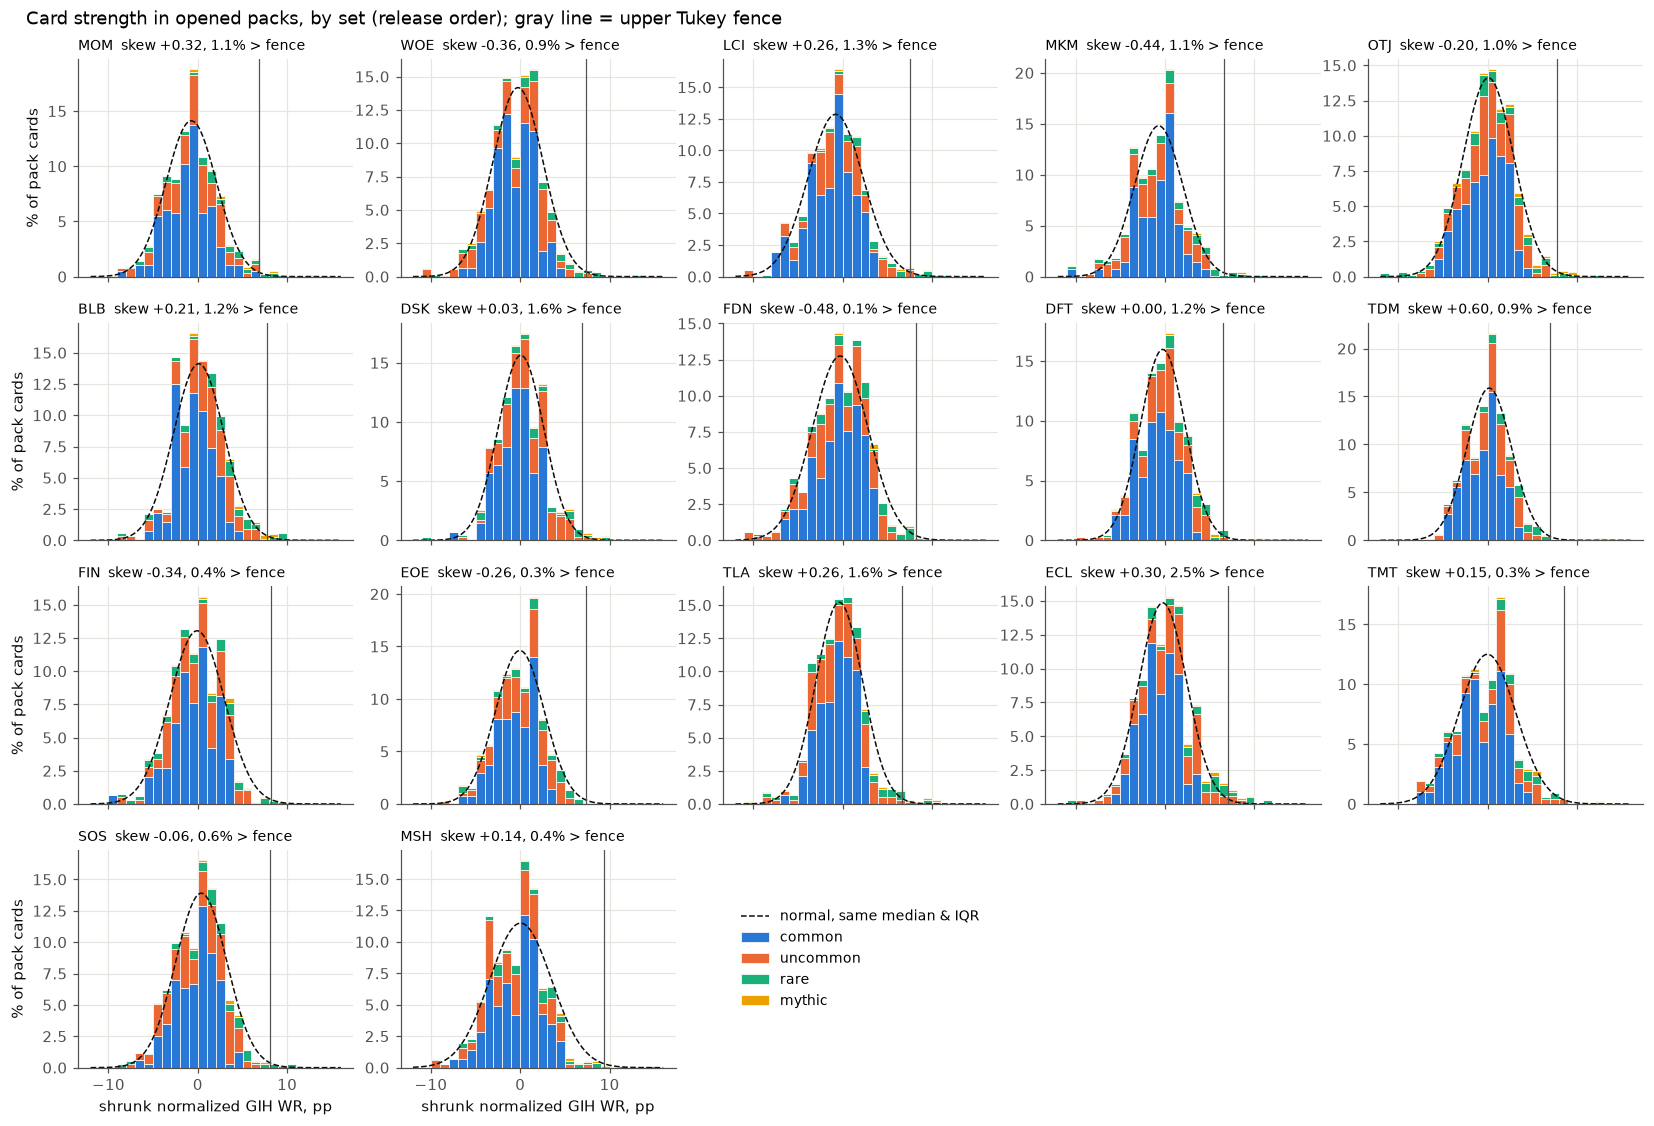

In [3]:
ncol = 5
nrow = -(-len(DRAFT_SETS) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 2.6 * nrow), sharex=True, squeeze=False)
bw = 1.0   # bin width, pp
bins = np.arange(-12, 16.01, bw)
xs = np.linspace(-12, 16, 400)
for ax, s in zip(axes.flat, DRAFT_SETS):
    d = seen.filter((pl.col("set") == s) & pl.col("norm_eb").is_not_null() & (pl.col("copies") > 0))
    total = d["copies"].sum()
    bottom = np.zeros(len(bins) - 1)
    for k in RARITIES:
        dk = d.filter(pl.col("rarity") == k)
        h, _ = np.histogram(dk["norm_eb"], bins, weights=dk["copies"].to_numpy() / total * 100)
        ax.bar(bins[:-1], h, width=bw, align="edge", bottom=bottom, color=R_COLOR[k], edgecolor=SURFACE, lw=0.5, label=k)
        bottom += h
    p = pack_dist.filter(pl.col("set") == s)
    q25, q75 = wquantile(d["norm_eb"].to_numpy(), d["copies"].to_numpy().astype(np.float64), [0.25, 0.75])
    sig = (q75 - q25) / 1.349
    ax.plot(xs, norm.pdf(xs, p["median"][0], sig) * bw * 100, color=INK, lw=1, ls="--", label="normal, same median & IQR")
    ax.axvline(p["median"][0] + FENCE_Z * sig, color=MUTED, lw=0.8)
    ax.set_title(f"{s}  skew {p['skew'][0]:+.2f}, {p['% > fence'][0]:.1f}% > fence", loc="left", fontsize=9)
for ax in axes.flat[len(DRAFT_SETS):]:
    ax.axis("off")
if len(DRAFT_SETS) < axes.size:   # legend in the first empty slot
    axes.flat[len(DRAFT_SETS)].legend(*axes.flat[0].get_legend_handles_labels(), loc="center", fontsize=9)
else:
    axes.flat[0].legend(fontsize=7.5, loc="upper left")
for ax in axes[:, 0]:
    ax.set_ylabel("% of pack cards")
for ax in axes[-1]:
    ax.set_xlabel("shrunk normalized GIH WR, pp")
fig.suptitle("Card strength in opened packs, by set (release order); gray line = upper Tukey fence", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

### 1b. All sets together: right tail vs left tail

Each set is put on its own robust z scale, (rating − median) / (IQR / 1.349), using pack-weighted quantiles, and every set
counts equally. On the right, the share of pack cards beyond $|z|$ in each tail is plotted on a log scale. A symmetric distribution would have the
two tails on top of each other, and a normal would follow the dashed line.

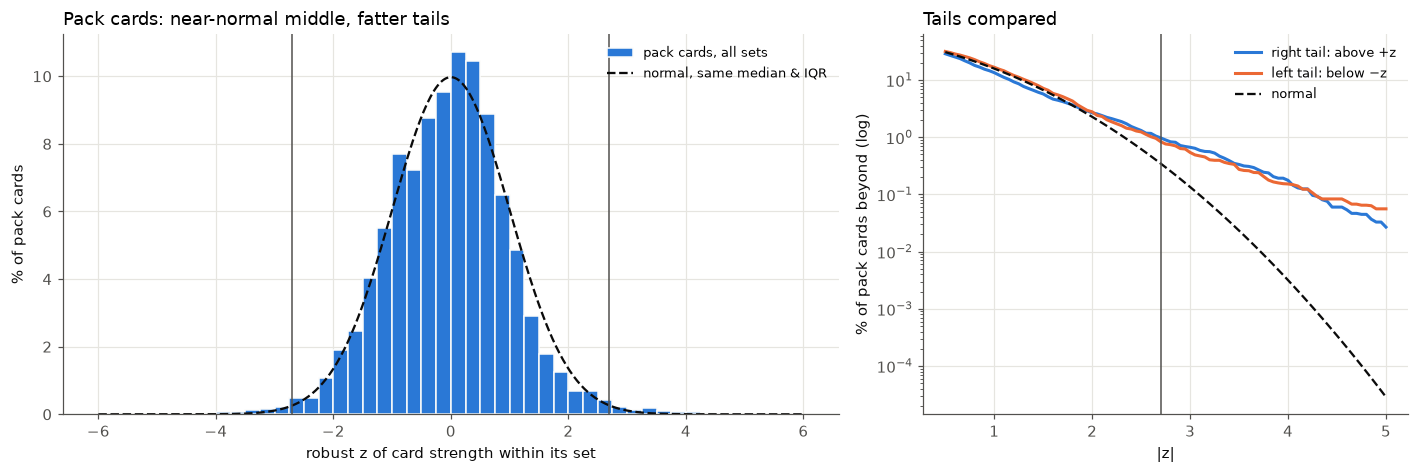

|z| > 2.00: right 2.68%, left 2.79%, normal 2.28% each side; right/left 1.0x
|z| > 2.70: right 0.97%, left 0.84%, normal 0.35% each side; right/left 1.2x
|z| > 3.00: right 0.67%, left 0.54%, normal 0.13% each side; right/left 1.2x
|z| > 3.50: right 0.33%, left 0.27%, normal 0.02% each side; right/left 1.2x
|z| > 4.00: right 0.18%, left 0.15%, normal 0.00% each side; right/left 1.2x


In [4]:
# all sets pooled on the robust z scale (each set's pack-weighted median and IQR), right tail vs left tail
zs, ws = [], []
for s in DRAFT_SETS:
    d = seen.filter((pl.col("set") == s) & pl.col("norm_eb").is_not_null() & (pl.col("copies") > 0))
    x, w = d["norm_eb"].to_numpy(), d["copies"].to_numpy().astype(np.float64)
    q25, q50, q75 = wquantile(x, w, [0.25, 0.5, 0.75])
    zs.append((x - q50) / ((q75 - q25) / 1.349)); ws.append(w / w.sum())   # each set counts equally
z, w = np.concatenate(zs), np.concatenate(ws) / len(DRAFT_SETS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
zb = np.arange(-6, 6.01, 0.25)
ax.hist(z, zb, weights=w * 100, color=BLUE, edgecolor=SURFACE, lw=1, label="pack cards, all sets")
zx = np.linspace(-6, 6, 400)
ax.plot(zx, norm.pdf(zx) * 0.25 * 100, color=INK, lw=1.5, ls="--", label="normal, same median & IQR")
ax.axvline(FENCE_Z, color=MUTED, lw=1); ax.axvline(-FENCE_Z, color=MUTED, lw=1)
ax.set_xlabel("robust z of card strength within its set"); ax.set_ylabel("% of pack cards")
ax.set_title("Pack cards: near-normal middle, fatter tails", loc="left"); ax.legend(fontsize=8.5)

ax = axes[1]
tt = np.linspace(0.5, 5, 91)
ax.semilogy(tt, [w[z > t].sum() * 100 for t in tt], color=BLUE, label="right tail: above +z")
ax.semilogy(tt, [w[z < -t].sum() * 100 for t in tt], color=ORANGE, label="left tail: below −z")
ax.semilogy(tt, norm.sf(tt) * 100, color=INK, ls="--", lw=1.5, label="normal")
ax.axvline(FENCE_Z, color=MUTED, lw=1)
ax.set_xlabel("|z|"); ax.set_ylabel("% of pack cards beyond (log)")
ax.set_title("Tails compared", loc="left"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

for t in [2.0, FENCE_Z, 3.0, 3.5, 4.0]:
    print(f"|z| > {t:.2f}: right {w[z > t].sum() * 100:.2f}%, left {w[z < -t].sum() * 100:.2f}%, "
          f"normal {norm.sf(t) * 100:.2f}% each side; right/left {w[z > t].sum() / max(w[z < -t].sum(), 1e-12):.1f}x")